Processing VP001...
Processing VP002...
Processing VP003...
Processing VP004...


C:\Users\SPACE\AppData\Local\Temp\ipykernel_20556\1167666047.py:130: RuntimeWarning: All epochs were dropped!
You might need to alter reject/flat-criteria or drop bad channels to avoid this. You can use Epochs.plot_drop_log() to see which channels are responsible for the dropping of epochs.
  epochs = mne.Epochs(


Processing VP005...
Processing VP006...
Processing VP007...
Processing VP008...
Processing VP009...
Processing VP010...
Processing VP011...
Processing VP012...
Processing VP013...
Processing VP014...
Processing VP015...
Processing VP016...
Processing VP017...
Processing VP018...
Processing VP019...
Processing VP020...
Processing VP021...
Processing VP022...
Processing VP023...
Processing VP024...
Processing VP025...
Processing VP026...

25 subjects used.
Total trials collected per class:
  0-back: 225 trials from 25 subjects
  2-back: 225 trials from 25 subjects
  3-back: 225 trials from 25 subjects
Identifying common channels ...
Identifying common channels ...
Identifying common channels ...


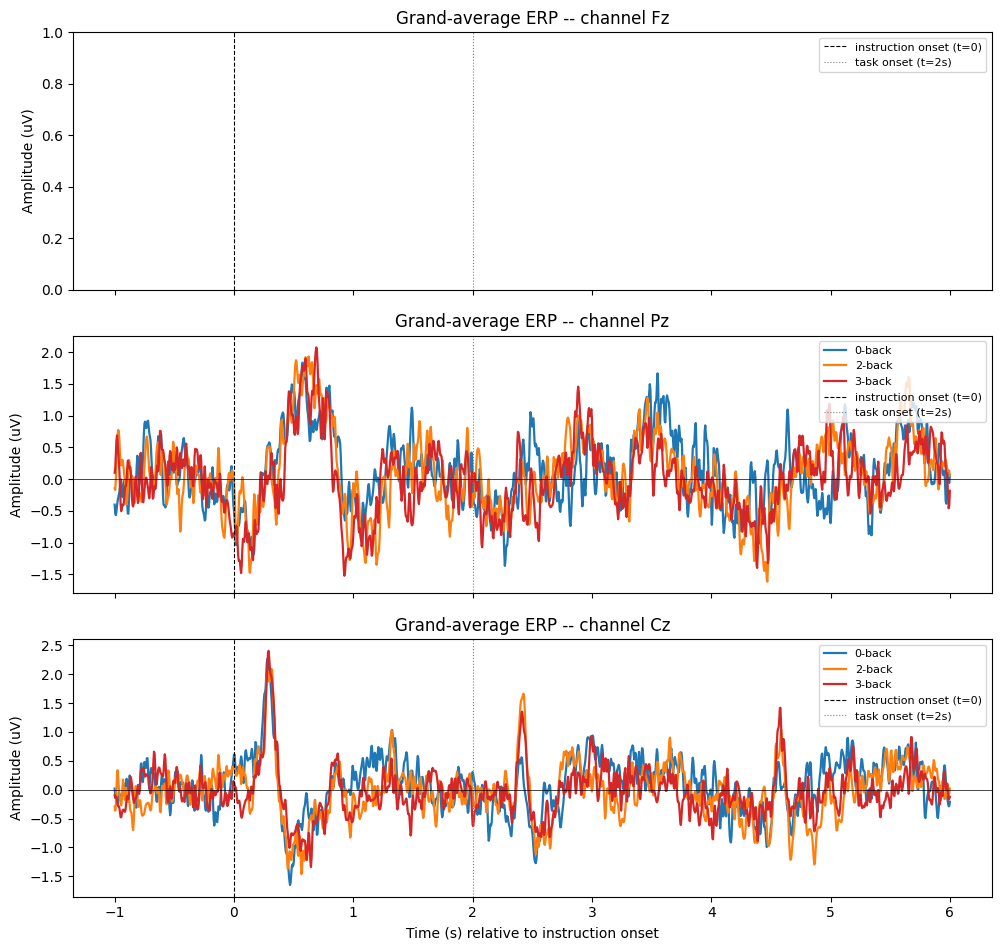


Plot also saved to run_d01_grand_average_erp.png

Mean amplitude per channel over [2.0, 6.0]s (uV):
    Fz: 0-back=N/A  2-back=N/A  3-back=N/A  
    Pz: 0-back=+0.12  2-back=+0.09  3-back=+0.01  
    Cz: 0-back=+0.08  2-back=-0.02  3-back=-0.02  


In [4]:
"""
Run D0.1 -- Sanity check with classic ERP
FULLY SELF-CONTAINED CELL -- paste this ENTIRE content into ONE new Jupyter cell and run it.
No other file/import needed (no dependency on preprocessing_v2_fixed.py).

WHAT IT DOES: plots grand-average ERP for a few frontal/parietal channels (Fz, Pz, Cz),
separately for the three n-back classes (0-back, 2-back, 3-back), using the cleaned continuous
EEG signal saved by preprocessing (each subject's {VP}_eeg_clean_raw.fif -- i.e. AFTER
notch+bandpass+bad-channel-interpolation+average-reference+ICA, BEFORE spatial mapping).

DECISION RULE (per the protocol):
  - If no visible difference between the three classes even in the averaged ERP -> the problem
    is at the signal/labeling level, not the architecture; go check Run D0.2 and D0.3 before
    touching the architecture.
  - If a difference IS visible in the averaged ERP but the model does not pick it up -> the
    problem really is architecture/windowing.

No GPU needed -- just matplotlib/mne/scipy on CPU, a few minutes.
"""

import os
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import mne

# ============================================================================
# EDIT THESE TO MATCH YOUR MAIN PREPROCESSING SCRIPT EXACTLY
# ============================================================================
BASE_DATASET_PATH = r"E:\kntu\Thesis\codes\DATA"                                  # raw dataset (needed only for re-reading markers)
OUTPUT_PATH       = r"F:\preprocessing-history-thesis\test0.0"       # where {VP}_eeg_clean_raw.fif files live

SUBJECTS = [f"VP{n:03d}" for n in range(1, 27)]   # narrow this down for a quicker test, e.g. range(1, 9)
CHANNELS = ['Fz', 'Pz', 'Cz']    # classic frontal/parietal/central channels for ERP
TMIN, TMAX = -1.0, 6.0           # seconds, relative to trial (instruction) onset
                                  # covers: 1s before instruction (baseline) to 6s after
                                  # (i.e. the 2s instruction + first 4s of the task period,
                                  # where a CNV/preparatory difference between load levels is
                                  # most expected)
BASELINE = (-1.0, 0.0)           # baseline correction window, before instruction onset
SFREQ_EEG = 200.0                # must match what preprocessing resampled EEG to
# ============================================================================

CLASS_NAMES = {0: '0-back', 1: '2-back', 2: '3-back'}
CLASS_COLORS = {0: 'tab:blue', 1: 'tab:orange', 2: 'tab:red'}
EEG_TRIAL_LABEL_MAP = {112: 0, 128: 1, 144: 2}   # trial-onset marker codes -> class (Shin et al. 2018)


def load_eeg_markers(eeg_folder):
    """Minimal, self-contained re-read of just the trial-onset markers (codes 112/128/144) from
    mrk_nback.mat, at the SAME 200Hz sample resolution the cleaned .fif files use. This mirrors
    (inlined here, no import) the marker-loading portion of load_eeg_data() in
    preprocessing_v2_fixed.py -- it does NOT re-filter/re-run ICA, it only needs cnt_nback.mat's
    original sampling rate (to convert marker times to sample indices) and mrk_nback.mat's codes.
    """
    cnt_path = os.path.join(eeg_folder, 'cnt_nback.mat')
    mrk_path = os.path.join(eeg_folder, 'mrk_nback.mat')

    mat_cnt = sio.loadmat(cnt_path, struct_as_record=False, squeeze_me=True)
    cnt_struct = mat_cnt[[k for k in mat_cnt.keys() if not k.startswith('__')][0]]
    sfreq_original = float(cnt_struct.fs)

    # Marker sample indices must be computed at the SAME sfreq the cleaned .fif was resampled to
    # (200Hz), exactly like preprocessing_v2_fixed.py's load_eeg_data() does (it updates its local
    # `sfreq` variable to SFREQ_EEG before computing event_positions).
    sfreq_for_markers = SFREQ_EEG if sfreq_original != SFREQ_EEG else sfreq_original

    mat_mrk = sio.loadmat(mrk_path, struct_as_record=False, squeeze_me=True)
    mrk_struct = mat_mrk[[k for k in mat_mrk.keys() if not k.startswith('__')][0]]

    if hasattr(mrk_struct, 'time'):
        event_positions = np.round(mrk_struct.time * sfreq_for_markers / 1000).astype(int)
    elif hasattr(mrk_struct, 'pos'):
        event_positions = np.array(mrk_struct.pos, dtype=int) - 1
    else:
        raise ValueError("Could not find 'time' or 'pos' in marker struct")

    if hasattr(mrk_struct, 'event') and hasattr(mrk_struct.event, 'desc'):
        desc = mrk_struct.event.desc
        if desc.ndim > 1:
            desc = desc.squeeze()
        event_codes = np.asarray(desc, dtype=int).flatten()
    else:
        event_codes = event_positions.copy()

    events = np.zeros((len(event_positions), 3), dtype=int)
    events[:, 0] = event_positions
    events[:, 2] = event_codes
    return events


evokeds_by_class = {0: [], 1: [], 2: []}   # each entry is one subject's averaged mne.Evoked
trial_counts_by_class = {0: 0, 1: 0, 2: 0}
n_subjects_used = 0

for subject_id in SUBJECTS:
    fif_path = os.path.join(OUTPUT_PATH, subject_id, f"{subject_id}_eeg_clean_raw.fif")
    if not os.path.exists(fif_path):
        print(f"  [SKIP] {subject_id}: {subject_id}_eeg_clean_raw.fif not found")
        continue

    eeg_folder = os.path.join(BASE_DATASET_PATH, f"{subject_id}-EEG")
    if not os.path.exists(eeg_folder):
        print(f"  [SKIP] {subject_id}: raw EEG folder not found (needed for markers)")
        continue

    print(f"Processing {subject_id}...")

    raw_clean = mne.io.read_raw_fif(fif_path, preload=True, verbose=False)

    picks_available = [ch for ch in CHANNELS if ch in raw_clean.ch_names]
    if not picks_available:
        print(f"  [SKIP] {subject_id}: none of {CHANNELS} present after preprocessing")
        continue

    try:
        events = load_eeg_markers(eeg_folder)
    except Exception as e:
        print(f"  [SKIP] {subject_id}: could not load markers: {e}")
        continue

    valid_codes = list(EEG_TRIAL_LABEL_MAP.keys())  # [112, 128, 144]
    target_events = events[np.isin(events[:, 2], valid_codes)]
    if len(target_events) == 0:
        print(f"  [SKIP] {subject_id}: no trial-level markers found")
        continue

    event_id = {str(code): code for code in valid_codes}
    try:
        epochs = mne.Epochs(
            raw_clean, target_events, event_id=event_id,
            tmin=TMIN, tmax=TMAX, baseline=BASELINE,
            picks=picks_available, preload=True, reject=None, verbose=False,
        )
    except Exception as e:
        print(f"  [SKIP] {subject_id}: error building epochs: {e}")
        continue

    subject_had_any = False
    for code, label in EEG_TRIAL_LABEL_MAP.items():
        key = str(code)
        if key not in epochs.event_id or len(epochs[key]) == 0:
            continue
        evk = epochs[key].average()
        evokeds_by_class[label].append(evk)
        trial_counts_by_class[label] += len(epochs[key])
        subject_had_any = True

    if subject_had_any:
        n_subjects_used += 1

print(f"\n{n_subjects_used} subjects used.")
print("Total trials collected per class:")
for label, name in CLASS_NAMES.items():
    print(f"  {name}: {trial_counts_by_class[label]} trials from {len(evokeds_by_class[label])} subjects")

if all(len(v) == 0 for v in evokeds_by_class.values()):
    raise RuntimeError("No evokeds were built for any class -- check paths / .fif files.")

# -- Grand average per class (mne auto-weights by each subject's trial count) --
grand_avg_by_class = {}
for label in CLASS_NAMES:
    if len(evokeds_by_class[label]) > 0:
        grand_avg_by_class[label] = mne.grand_average(evokeds_by_class[label])

# -- Plot: one subplot per channel, three classes overlaid --
fig, axes = plt.subplots(len(CHANNELS), 1, figsize=(10, 3.2 * len(CHANNELS)), sharex=True)
if len(CHANNELS) == 1:
    axes = [axes]

for ax, ch_name in zip(axes, CHANNELS):
    for label, name in CLASS_NAMES.items():
        if label not in grand_avg_by_class:
            continue
        evk = grand_avg_by_class[label]
        if ch_name not in evk.ch_names:
            continue
        ch_idx = evk.ch_names.index(ch_name)
        data_uv = evk.data[ch_idx] * 1e6   # volts -> microvolts for readability
        ax.plot(evk.times, data_uv, color=CLASS_COLORS[label], linewidth=1.6, label=name)

    ax.axvline(0.0, color='k', linestyle='--', linewidth=0.8, label='instruction onset (t=0)')
    ax.axvline(2.0, color='gray', linestyle=':', linewidth=0.8, label='task onset (t=2s)')
    ax.axhline(0.0, color='k', linewidth=0.5)
    ax.set_title(f"Grand-average ERP -- channel {ch_name}")
    ax.set_ylabel("Amplitude (uV)")
    ax.legend(loc='upper right', fontsize=8)

axes[-1].set_xlabel("Time (s) relative to instruction onset")
plt.tight_layout()
plt.savefig("run_d01_grand_average_erp.png", dpi=150)
plt.show()
print("\nPlot also saved to run_d01_grand_average_erp.png")

# -- Quick numeric summary: mean amplitude over a fixed window, for a quantitative comparison --
SUMMARY_TMIN, SUMMARY_TMAX = 2.0, 6.0  # same early-task-period window
print(f"\nMean amplitude per channel over [{SUMMARY_TMIN}, {SUMMARY_TMAX}]s (uV):")
for ch_name in CHANNELS:
    row = f"  {ch_name:>4}: "
    for label, name in CLASS_NAMES.items():
        if label not in grand_avg_by_class or ch_name not in grand_avg_by_class[label].ch_names:
            row += f"{name}=N/A  "
            continue
        evk = grand_avg_by_class[label]
        ch_idx = evk.ch_names.index(ch_name)
        mask = (evk.times >= SUMMARY_TMIN) & (evk.times <= SUMMARY_TMAX)
        mean_uv = evk.data[ch_idx, mask].mean() * 1e6
        row += f"{name}={mean_uv:+.2f}  "
    print(row)

Processing VP001...
Processing VP002...
Processing VP003...
Processing VP004...


C:\Users\SPACE\AppData\Local\Temp\ipykernel_20556\1342812180.py:136: RuntimeWarning: All epochs were dropped!
You might need to alter reject/flat-criteria or drop bad channels to avoid this. You can use Epochs.plot_drop_log() to see which channels are responsible for the dropping of epochs.
  epochs = mne.Epochs(


Processing VP005...
Processing VP006...
Processing VP007...
Processing VP008...
Processing VP009...
Processing VP010...
Processing VP011...
Processing VP012...
Processing VP013...
Processing VP014...
Processing VP015...
Processing VP016...
Processing VP017...
Processing VP018...
Processing VP019...
Processing VP020...
Processing VP021...
Processing VP022...
Processing VP023...
Processing VP024...
Processing VP025...
Processing VP026...

25 subjects used.
Total trials collected per class:
  0-back: 225 trials from 25 subjects
  2-back: 225 trials from 25 subjects
  3-back: 225 trials from 25 subjects
Identifying common channels ...
Identifying common channels ...
Identifying common channels ...


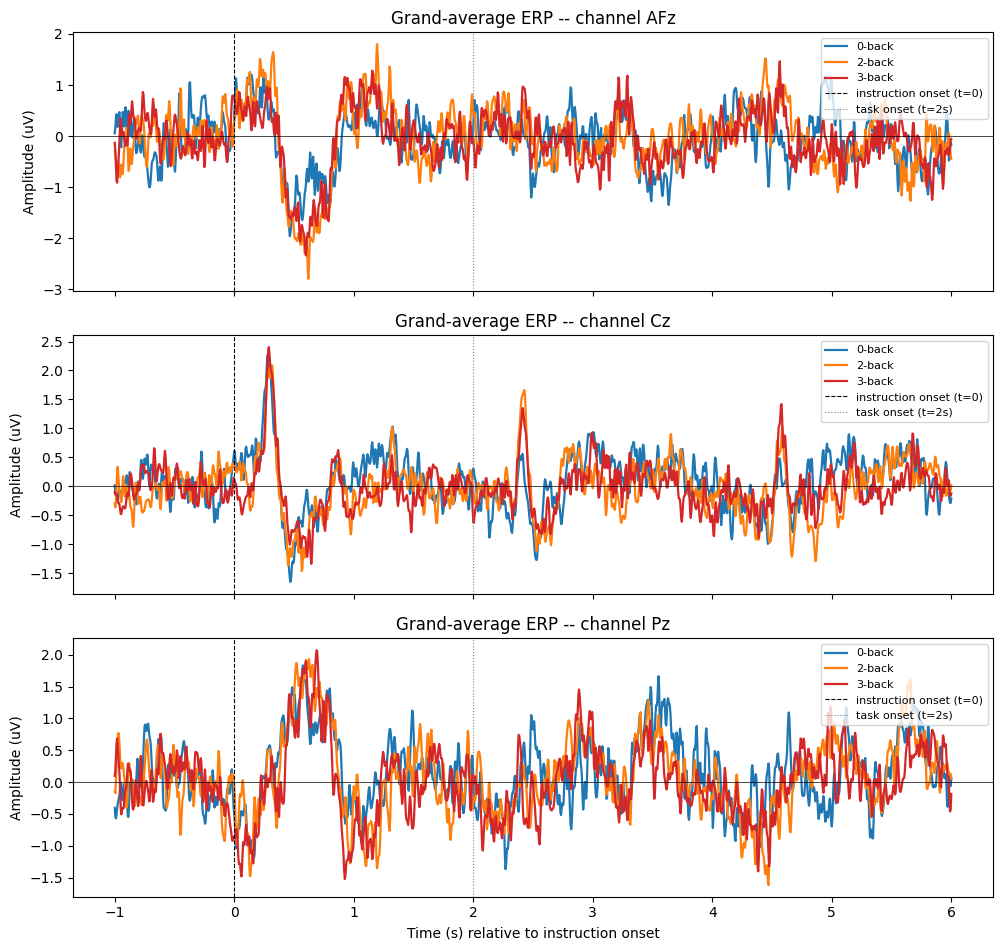


Plot also saved to run_d01_grand_average_erp.png

Mean amplitude per channel over [2.0, 6.0]s (uV):
   AFz: 0-back=-0.07  2-back=-0.04  3-back=-0.09  
    Cz: 0-back=+0.08  2-back=-0.02  3-back=-0.02  
    Pz: 0-back=+0.12  2-back=+0.09  3-back=+0.01  


In [5]:
"""
Run D0.1 -- Sanity check with classic ERP
FULLY SELF-CONTAINED CELL -- paste this ENTIRE content into ONE new Jupyter cell and run it.
No other file/import needed (no dependency on preprocessing_v2_fixed.py).

WHAT IT DOES: plots grand-average ERP for a few frontal/parietal channels (Fz, Pz, Cz),
separately for the three n-back classes (0-back, 2-back, 3-back), using the cleaned continuous
EEG signal saved by preprocessing (each subject's {VP}_eeg_clean_raw.fif -- i.e. AFTER
notch+bandpass+bad-channel-interpolation+average-reference+ICA, BEFORE spatial mapping).

DECISION RULE (per the protocol):
  - If no visible difference between the three classes even in the averaged ERP -> the problem
    is at the signal/labeling level, not the architecture; go check Run D0.2 and D0.3 before
    touching the architecture.
  - If a difference IS visible in the averaged ERP but the model does not pick it up -> the
    problem really is architecture/windowing.

No GPU needed -- just matplotlib/mne/scipy on CPU, a few minutes.
"""

import os
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import mne

# ============================================================================
# EDIT THESE TO MATCH YOUR MAIN PREPROCESSING SCRIPT EXACTLY
# ============================================================================
BASE_DATASET_PATH = r"E:\kntu\Thesis\codes\DATA"                                  # raw dataset (needed only for re-reading markers)
OUTPUT_PATH       = r"F:\preprocessing-history-thesis\test0.0"       # where {VP}_eeg_clean_raw.fif files live

SUBJECTS = [f"VP{n:03d}" for n in range(1, 27)]   # narrow this down for a quicker test, e.g. range(1, 9)
CHANNELS = ['AFz', 'Cz', 'Pz']    # classic frontal/parietal/central channels for ERP
                                  # NOTE: this dataset's 30-channel montage has NO electrode
                                  # literally named "Fz" (see data_description.md's channel list:
                                  # Fp1, Fp2, AFF5h, AFF6h, AFz, F1, F2, FC1, FC2, FC5, FC6, Cz,
                                  # C3, C4, T7, T8, CP1, CP2, CP5, CP6, Pz, P3, P4, P7, P8, POz,
                                  # O1, O2, TP9, TP10) -- AFz is the closest midline-frontal
                                  # electrode actually present, used here instead.
TMIN, TMAX = -1.0, 6.0           # seconds, relative to trial (instruction) onset
                                  # covers: 1s before instruction (baseline) to 6s after
                                  # (i.e. the 2s instruction + first 4s of the task period,
                                  # where a CNV/preparatory difference between load levels is
                                  # most expected)
BASELINE = (-1.0, 0.0)           # baseline correction window, before instruction onset
SFREQ_EEG = 200.0                # must match what preprocessing resampled EEG to
# ============================================================================

CLASS_NAMES = {0: '0-back', 1: '2-back', 2: '3-back'}
CLASS_COLORS = {0: 'tab:blue', 1: 'tab:orange', 2: 'tab:red'}
EEG_TRIAL_LABEL_MAP = {112: 0, 128: 1, 144: 2}   # trial-onset marker codes -> class (Shin et al. 2018)


def load_eeg_markers(eeg_folder):
    """Minimal, self-contained re-read of just the trial-onset markers (codes 112/128/144) from
    mrk_nback.mat, at the SAME 200Hz sample resolution the cleaned .fif files use. This mirrors
    (inlined here, no import) the marker-loading portion of load_eeg_data() in
    preprocessing_v2_fixed.py -- it does NOT re-filter/re-run ICA, it only needs cnt_nback.mat's
    original sampling rate (to convert marker times to sample indices) and mrk_nback.mat's codes.
    """
    cnt_path = os.path.join(eeg_folder, 'cnt_nback.mat')
    mrk_path = os.path.join(eeg_folder, 'mrk_nback.mat')

    mat_cnt = sio.loadmat(cnt_path, struct_as_record=False, squeeze_me=True)
    cnt_struct = mat_cnt[[k for k in mat_cnt.keys() if not k.startswith('__')][0]]
    sfreq_original = float(cnt_struct.fs)

    # Marker sample indices must be computed at the SAME sfreq the cleaned .fif was resampled to
    # (200Hz), exactly like preprocessing_v2_fixed.py's load_eeg_data() does (it updates its local
    # `sfreq` variable to SFREQ_EEG before computing event_positions).
    sfreq_for_markers = SFREQ_EEG if sfreq_original != SFREQ_EEG else sfreq_original

    mat_mrk = sio.loadmat(mrk_path, struct_as_record=False, squeeze_me=True)
    mrk_struct = mat_mrk[[k for k in mat_mrk.keys() if not k.startswith('__')][0]]

    if hasattr(mrk_struct, 'time'):
        event_positions = np.round(mrk_struct.time * sfreq_for_markers / 1000).astype(int)
    elif hasattr(mrk_struct, 'pos'):
        event_positions = np.array(mrk_struct.pos, dtype=int) - 1
    else:
        raise ValueError("Could not find 'time' or 'pos' in marker struct")

    if hasattr(mrk_struct, 'event') and hasattr(mrk_struct.event, 'desc'):
        desc = mrk_struct.event.desc
        if desc.ndim > 1:
            desc = desc.squeeze()
        event_codes = np.asarray(desc, dtype=int).flatten()
    else:
        event_codes = event_positions.copy()

    events = np.zeros((len(event_positions), 3), dtype=int)
    events[:, 0] = event_positions
    events[:, 2] = event_codes
    return events


evokeds_by_class = {0: [], 1: [], 2: []}   # each entry is one subject's averaged mne.Evoked
trial_counts_by_class = {0: 0, 1: 0, 2: 0}
n_subjects_used = 0

for subject_id in SUBJECTS:
    fif_path = os.path.join(OUTPUT_PATH, subject_id, f"{subject_id}_eeg_clean_raw.fif")
    if not os.path.exists(fif_path):
        print(f"  [SKIP] {subject_id}: {subject_id}_eeg_clean_raw.fif not found")
        continue

    eeg_folder = os.path.join(BASE_DATASET_PATH, f"{subject_id}-EEG")
    if not os.path.exists(eeg_folder):
        print(f"  [SKIP] {subject_id}: raw EEG folder not found (needed for markers)")
        continue

    print(f"Processing {subject_id}...")

    raw_clean = mne.io.read_raw_fif(fif_path, preload=True, verbose=False)

    picks_available = [ch for ch in CHANNELS if ch in raw_clean.ch_names]
    if not picks_available:
        print(f"  [SKIP] {subject_id}: none of {CHANNELS} present after preprocessing")
        continue

    try:
        events = load_eeg_markers(eeg_folder)
    except Exception as e:
        print(f"  [SKIP] {subject_id}: could not load markers: {e}")
        continue

    valid_codes = list(EEG_TRIAL_LABEL_MAP.keys())  # [112, 128, 144]
    target_events = events[np.isin(events[:, 2], valid_codes)]
    if len(target_events) == 0:
        print(f"  [SKIP] {subject_id}: no trial-level markers found")
        continue

    event_id = {str(code): code for code in valid_codes}
    try:
        epochs = mne.Epochs(
            raw_clean, target_events, event_id=event_id,
            tmin=TMIN, tmax=TMAX, baseline=BASELINE,
            picks=picks_available, preload=True, reject=None, verbose=False,
        )
    except Exception as e:
        print(f"  [SKIP] {subject_id}: error building epochs: {e}")
        continue

    subject_had_any = False
    for code, label in EEG_TRIAL_LABEL_MAP.items():
        key = str(code)
        if key not in epochs.event_id or len(epochs[key]) == 0:
            continue
        evk = epochs[key].average()
        evokeds_by_class[label].append(evk)
        trial_counts_by_class[label] += len(epochs[key])
        subject_had_any = True

    if subject_had_any:
        n_subjects_used += 1

print(f"\n{n_subjects_used} subjects used.")
print("Total trials collected per class:")
for label, name in CLASS_NAMES.items():
    print(f"  {name}: {trial_counts_by_class[label]} trials from {len(evokeds_by_class[label])} subjects")

if all(len(v) == 0 for v in evokeds_by_class.values()):
    raise RuntimeError("No evokeds were built for any class -- check paths / .fif files.")

# -- Grand average per class (mne auto-weights by each subject's trial count) --
grand_avg_by_class = {}
for label in CLASS_NAMES:
    if len(evokeds_by_class[label]) > 0:
        grand_avg_by_class[label] = mne.grand_average(evokeds_by_class[label])

# -- Plot: one subplot per channel, three classes overlaid --
fig, axes = plt.subplots(len(CHANNELS), 1, figsize=(10, 3.2 * len(CHANNELS)), sharex=True)
if len(CHANNELS) == 1:
    axes = [axes]

for ax, ch_name in zip(axes, CHANNELS):
    for label, name in CLASS_NAMES.items():
        if label not in grand_avg_by_class:
            continue
        evk = grand_avg_by_class[label]
        if ch_name not in evk.ch_names:
            continue
        ch_idx = evk.ch_names.index(ch_name)
        data_uv = evk.data[ch_idx] * 1e6   # volts -> microvolts for readability
        ax.plot(evk.times, data_uv, color=CLASS_COLORS[label], linewidth=1.6, label=name)

    ax.axvline(0.0, color='k', linestyle='--', linewidth=0.8, label='instruction onset (t=0)')
    ax.axvline(2.0, color='gray', linestyle=':', linewidth=0.8, label='task onset (t=2s)')
    ax.axhline(0.0, color='k', linewidth=0.5)
    ax.set_title(f"Grand-average ERP -- channel {ch_name}")
    ax.set_ylabel("Amplitude (uV)")
    ax.legend(loc='upper right', fontsize=8)

axes[-1].set_xlabel("Time (s) relative to instruction onset")
plt.tight_layout()
plt.savefig("run_d01_grand_average_erp.png", dpi=150)
plt.show()
print("\nPlot also saved to run_d01_grand_average_erp.png")

# -- Quick numeric summary: mean amplitude over a fixed window, for a quantitative comparison --
SUMMARY_TMIN, SUMMARY_TMAX = 2.0, 6.0  # same early-task-period window
print(f"\nMean amplitude per channel over [{SUMMARY_TMIN}, {SUMMARY_TMAX}]s (uV):")
for ch_name in CHANNELS:
    row = f"  {ch_name:>4}: "
    for label, name in CLASS_NAMES.items():
        if label not in grand_avg_by_class or ch_name not in grand_avg_by_class[label].ch_names:
            row += f"{name}=N/A  "
            continue
        evk = grand_avg_by_class[label]
        ch_idx = evk.ch_names.index(ch_name)
        mask = (evk.times >= SUMMARY_TMIN) & (evk.times <= SUMMARY_TMAX)
        mean_uv = evk.data[ch_idx, mask].mean() * 1e6
        row += f"{name}={mean_uv:+.2f}  "
    print(row)

Processing VP001...
Processing VP002...
Processing VP003...
Processing VP004...


C:\Users\SPACE\AppData\Local\Temp\ipykernel_20556\3626322616.py:136: RuntimeWarning: All epochs were dropped!
You might need to alter reject/flat-criteria or drop bad channels to avoid this. You can use Epochs.plot_drop_log() to see which channels are responsible for the dropping of epochs.
  epochs = mne.Epochs(


  [INFO] VP004: 0/27 epochs survived (likely all overlap BAD_* annotations, or fall outside the recording) -- skipped
Processing VP005...
Processing VP006...
Processing VP007...
Processing VP008...
Processing VP009...
Processing VP010...
Processing VP011...
Processing VP012...
Processing VP013...
Processing VP014...
Processing VP015...
Processing VP016...
Processing VP017...
Processing VP018...
Processing VP019...
Processing VP020...
Processing VP021...
Processing VP022...
Processing VP023...
Processing VP024...
Processing VP025...
Processing VP026...

25 subjects used.
Total trials collected per class:
  0-back: 225 trials from 25 subjects
  2-back: 225 trials from 25 subjects
  3-back: 225 trials from 25 subjects
Identifying common channels ...
Identifying common channels ...
Identifying common channels ...


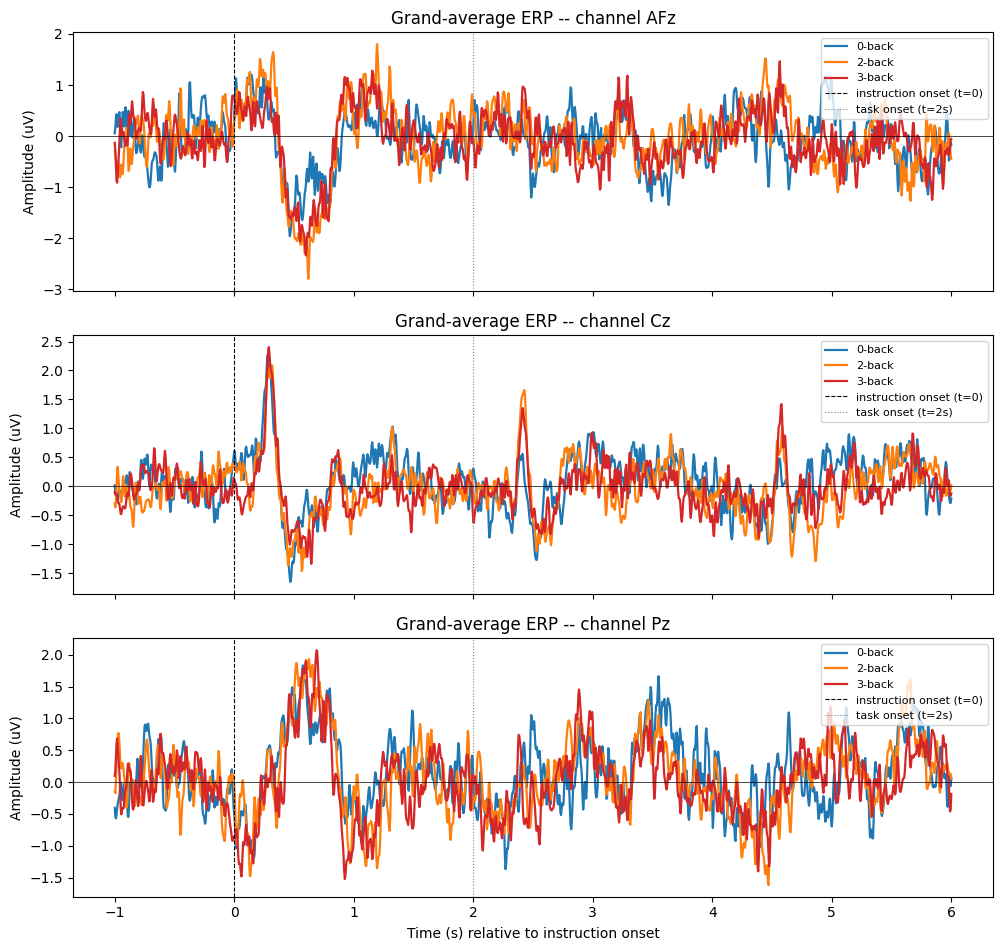


Plot also saved to run_d01_grand_average_erp.png

Mean amplitude per channel over [2.0, 6.0]s (uV):
   AFz: 0-back=-0.07  2-back=-0.04  3-back=-0.09  
    Cz: 0-back=+0.08  2-back=-0.02  3-back=-0.02  
    Pz: 0-back=+0.12  2-back=+0.09  3-back=+0.01  


In [8]:
"""
Run D0.1 -- Sanity check with classic ERP
FULLY SELF-CONTAINED CELL -- paste this ENTIRE content into ONE new Jupyter cell and run it.
No other file/import needed (no dependency on preprocessing_v2_fixed.py).

WHAT IT DOES: plots grand-average ERP for a few frontal/parietal channels (Fz, Pz, Cz),
separately for the three n-back classes (0-back, 2-back, 3-back), using the cleaned continuous
EEG signal saved by preprocessing (each subject's {VP}_eeg_clean_raw.fif -- i.e. AFTER
notch+bandpass+bad-channel-interpolation+average-reference+ICA, BEFORE spatial mapping).

DECISION RULE (per the protocol):
  - If no visible difference between the three classes even in the averaged ERP -> the problem
    is at the signal/labeling level, not the architecture; go check Run D0.2 and D0.3 before
    touching the architecture.
  - If a difference IS visible in the averaged ERP but the model does not pick it up -> the
    problem really is architecture/windowing.

No GPU needed -- just matplotlib/mne/scipy on CPU, a few minutes.
"""

import os
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import mne

# ============================================================================
# EDIT THESE TO MATCH YOUR MAIN PREPROCESSING SCRIPT EXACTLY
# ============================================================================
BASE_DATASET_PATH = r"E:\kntu\Thesis\codes\DATA"                                  # raw dataset (needed only for re-reading markers)
OUTPUT_PATH       = r"F:\preprocessing-history-thesis\test0.0"       # where {VP}_eeg_clean_raw.fif files live

SUBJECTS = [f"VP{n:03d}" for n in range(1, 27)]   # narrow this down for a quicker test, e.g. range(1, 9)
CHANNELS = ['AFz', 'Cz', 'Pz']    # classic frontal/parietal/central channels for ERP
                                  # NOTE: this dataset's 30-channel montage has NO electrode
                                  # literally named "Fz" (see data_description.md's channel list:
                                  # Fp1, Fp2, AFF5h, AFF6h, AFz, F1, F2, FC1, FC2, FC5, FC6, Cz,
                                  # C3, C4, T7, T8, CP1, CP2, CP5, CP6, Pz, P3, P4, P7, P8, POz,
                                  # O1, O2, TP9, TP10) -- AFz is the closest midline-frontal
                                  # electrode actually present, used here instead.
TMIN, TMAX = -1.0, 6.0           # seconds, relative to trial (instruction) onset
                                  # covers: 1s before instruction (baseline) to 6s after
                                  # (i.e. the 2s instruction + first 4s of the task period,
                                  # where a CNV/preparatory difference between load levels is
                                  # most expected)
BASELINE = (-1.0, 0.0)           # baseline correction window, before instruction onset
SFREQ_EEG = 200.0                # must match what preprocessing resampled EEG to
# ============================================================================

CLASS_NAMES = {0: '0-back', 1: '2-back', 2: '3-back'}
CLASS_COLORS = {0: 'tab:blue', 1: 'tab:orange', 2: 'tab:red'}
EEG_TRIAL_LABEL_MAP = {112: 0, 128: 1, 144: 2}   # trial-onset marker codes -> class (Shin et al. 2018)


def load_eeg_markers(eeg_folder):
    """Minimal, self-contained re-read of just the trial-onset markers (codes 112/128/144) from
    mrk_nback.mat, at the SAME 200Hz sample resolution the cleaned .fif files use. This mirrors
    (inlined here, no import) the marker-loading portion of load_eeg_data() in
    preprocessing_v2_fixed.py -- it does NOT re-filter/re-run ICA, it only needs cnt_nback.mat's
    original sampling rate (to convert marker times to sample indices) and mrk_nback.mat's codes.
    """
    cnt_path = os.path.join(eeg_folder, 'cnt_nback.mat')
    mrk_path = os.path.join(eeg_folder, 'mrk_nback.mat')

    mat_cnt = sio.loadmat(cnt_path, struct_as_record=False, squeeze_me=True)
    cnt_struct = mat_cnt[[k for k in mat_cnt.keys() if not k.startswith('__')][0]]
    sfreq_original = float(cnt_struct.fs)

    # Marker sample indices must be computed at the SAME sfreq the cleaned .fif was resampled to
    # (200Hz), exactly like preprocessing_v2_fixed.py's load_eeg_data() does (it updates its local
    # `sfreq` variable to SFREQ_EEG before computing event_positions).
    sfreq_for_markers = SFREQ_EEG if sfreq_original != SFREQ_EEG else sfreq_original

    mat_mrk = sio.loadmat(mrk_path, struct_as_record=False, squeeze_me=True)
    mrk_struct = mat_mrk[[k for k in mat_mrk.keys() if not k.startswith('__')][0]]

    if hasattr(mrk_struct, 'time'):
        event_positions = np.round(mrk_struct.time * sfreq_for_markers / 1000).astype(int)
    elif hasattr(mrk_struct, 'pos'):
        event_positions = np.array(mrk_struct.pos, dtype=int) - 1
    else:
        raise ValueError("Could not find 'time' or 'pos' in marker struct")

    if hasattr(mrk_struct, 'event') and hasattr(mrk_struct.event, 'desc'):
        desc = mrk_struct.event.desc
        if desc.ndim > 1:
            desc = desc.squeeze()
        event_codes = np.asarray(desc, dtype=int).flatten()
    else:
        event_codes = event_positions.copy()

    events = np.zeros((len(event_positions), 3), dtype=int)
    events[:, 0] = event_positions
    events[:, 2] = event_codes
    return events


evokeds_by_class = {0: [], 1: [], 2: []}   # each entry is one subject's averaged mne.Evoked
trial_counts_by_class = {0: 0, 1: 0, 2: 0}
n_subjects_used = 0

for subject_id in SUBJECTS:
    fif_path = os.path.join(OUTPUT_PATH, subject_id, f"{subject_id}_eeg_clean_raw.fif")
    if not os.path.exists(fif_path):
        print(f"  [SKIP] {subject_id}: {subject_id}_eeg_clean_raw.fif not found")
        continue

    eeg_folder = os.path.join(BASE_DATASET_PATH, f"{subject_id}-EEG")
    if not os.path.exists(eeg_folder):
        print(f"  [SKIP] {subject_id}: raw EEG folder not found (needed for markers)")
        continue

    print(f"Processing {subject_id}...")

    raw_clean = mne.io.read_raw_fif(fif_path, preload=True, verbose=False)

    picks_available = [ch for ch in CHANNELS if ch in raw_clean.ch_names]
    if not picks_available:
        print(f"  [SKIP] {subject_id}: none of {CHANNELS} present after preprocessing")
        continue

    try:
        events = load_eeg_markers(eeg_folder)
    except Exception as e:
        print(f"  [SKIP] {subject_id}: could not load markers: {e}")
        continue

    valid_codes = list(EEG_TRIAL_LABEL_MAP.keys())  # [112, 128, 144]
    target_events = events[np.isin(events[:, 2], valid_codes)]
    if len(target_events) == 0:
        print(f"  [SKIP] {subject_id}: no trial-level markers found")
        continue

    event_id = {str(code): code for code in valid_codes}
    try:
        epochs = mne.Epochs(
            raw_clean, target_events, event_id=event_id,
            tmin=TMIN, tmax=TMAX, baseline=BASELINE,
            picks=picks_available, preload=True, reject=None, verbose=False,
        )
    except Exception as e:
        print(f"  [SKIP] {subject_id}: error building epochs: {e}")
        continue

    # NEW: explicitly attribute an all-epochs-dropped case to this subject_id. MNE's own
    # "All epochs were dropped!" RuntimeWarning (printed above, if it happens) does not mention
    # which subject triggered it, so this makes it unambiguous which subject to blame -- most
    # likely cause: this subject's .fif has BAD_amplitude annotations (from a strict-noise
    # reprocessing pass) covering all/most of the recording, and mne.Epochs excludes any epoch
    # overlapping a BAD_* annotation by default (reject_by_annotation=True).
    if len(epochs) == 0:
        print(f"  [INFO] {subject_id}: 0/{len(target_events)} epochs survived "
              f"(likely all overlap BAD_* annotations, or fall outside the recording) -- skipped")
        continue

    subject_had_any = False
    for code, label in EEG_TRIAL_LABEL_MAP.items():
        key = str(code)
        if key not in epochs.event_id or len(epochs[key]) == 0:
            continue
        evk = epochs[key].average()
        evokeds_by_class[label].append(evk)
        trial_counts_by_class[label] += len(epochs[key])
        subject_had_any = True

    if subject_had_any:
        n_subjects_used += 1

print(f"\n{n_subjects_used} subjects used.")
print("Total trials collected per class:")
for label, name in CLASS_NAMES.items():
    print(f"  {name}: {trial_counts_by_class[label]} trials from {len(evokeds_by_class[label])} subjects")

if all(len(v) == 0 for v in evokeds_by_class.values()):
    raise RuntimeError("No evokeds were built for any class -- check paths / .fif files.")

# -- Grand average per class (mne auto-weights by each subject's trial count) --
grand_avg_by_class = {}
for label in CLASS_NAMES:
    if len(evokeds_by_class[label]) > 0:
        grand_avg_by_class[label] = mne.grand_average(evokeds_by_class[label])

# -- Plot: one subplot per channel, three classes overlaid --
fig, axes = plt.subplots(len(CHANNELS), 1, figsize=(10, 3.2 * len(CHANNELS)), sharex=True)
if len(CHANNELS) == 1:
    axes = [axes]

for ax, ch_name in zip(axes, CHANNELS):
    for label, name in CLASS_NAMES.items():
        if label not in grand_avg_by_class:
            continue
        evk = grand_avg_by_class[label]
        if ch_name not in evk.ch_names:
            continue
        ch_idx = evk.ch_names.index(ch_name)
        data_uv = evk.data[ch_idx] * 1e6   # volts -> microvolts for readability
        ax.plot(evk.times, data_uv, color=CLASS_COLORS[label], linewidth=1.6, label=name)

    ax.axvline(0.0, color='k', linestyle='--', linewidth=0.8, label='instruction onset (t=0)')
    ax.axvline(2.0, color='gray', linestyle=':', linewidth=0.8, label='task onset (t=2s)')
    ax.axhline(0.0, color='k', linewidth=0.5)
    ax.set_title(f"Grand-average ERP -- channel {ch_name}")
    ax.set_ylabel("Amplitude (uV)")
    ax.legend(loc='upper right', fontsize=8)

axes[-1].set_xlabel("Time (s) relative to instruction onset")
plt.tight_layout()
plt.savefig("run_d01_grand_average_erp.png", dpi=150)
plt.show()
print("\nPlot also saved to run_d01_grand_average_erp.png")

# -- Quick numeric summary: mean amplitude over a fixed window, for a quantitative comparison --
SUMMARY_TMIN, SUMMARY_TMAX = 2.0, 6.0  # same early-task-period window
print(f"\nMean amplitude per channel over [{SUMMARY_TMIN}, {SUMMARY_TMAX}]s (uV):")
for ch_name in CHANNELS:
    row = f"  {ch_name:>4}: "
    for label, name in CLASS_NAMES.items():
        if label not in grand_avg_by_class or ch_name not in grand_avg_by_class[label].ch_names:
            row += f"{name}=N/A  "
            continue
        evk = grand_avg_by_class[label]
        ch_idx = evk.ch_names.index(ch_name)
        mask = (evk.times >= SUMMARY_TMIN) & (evk.times <= SUMMARY_TMAX)
        mean_uv = evk.data[ch_idx, mask].mean() * 1e6
        row += f"{name}={mean_uv:+.2f}  "
    print(row)

Processing VP001...
Processing VP002...
Processing VP003...
Processing VP004...
Processing VP005...
Processing VP006...
Processing VP007...
Processing VP008...
Processing VP009...
Processing VP010...
Processing VP011...
Processing VP012...
Processing VP013...
Processing VP014...
Processing VP015...
Processing VP016...
Processing VP017...
Processing VP018...
Processing VP019...
Processing VP020...
Processing VP021...
Processing VP022...
Processing VP023...
Processing VP024...
Processing VP025...
Processing VP026...

26 subjects used.
Total stimulus-level epochs collected per class:
  0-back: 4538 epochs from 26 subjects
  2-back: 4516 epochs from 52 subjects
  3-back: 4514 epochs from 52 subjects
Identifying common channels ...
Identifying common channels ...
Identifying common channels ...


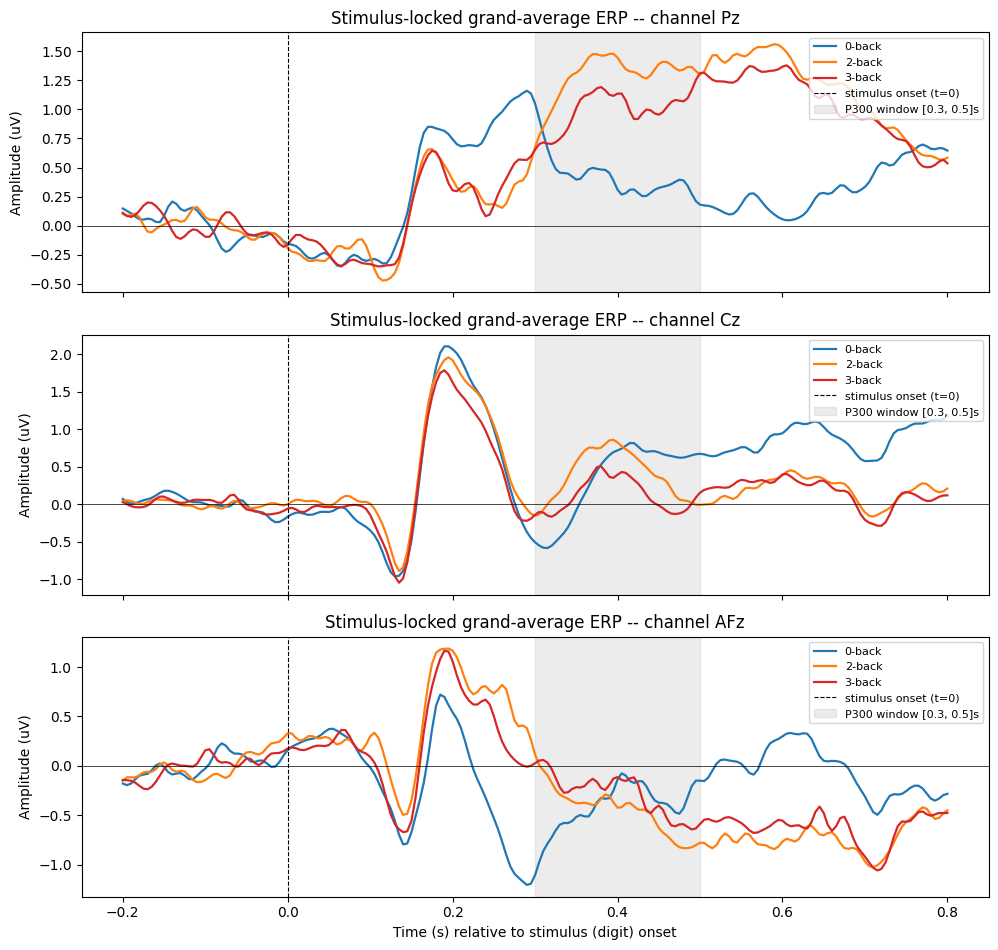


Plot also saved to run_d01b_stimulus_locked_erp.png

Mean P300-window amplitude per channel over (0.3, 0.5)s (uV):
    Pz: 0-back=+0.42  2-back=+1.29  3-back=+1.00  
        ordering: 2-back > 3-back > 0-back  (not monotonic)
    Cz: 0-back=+0.33  2-back=+0.39  3-back=+0.12  
        ordering: 2-back > 0-back > 3-back  (not monotonic)
   AFz: 0-back=-0.42  2-back=-0.44  3-back=-0.28  
        ordering: 3-back > 0-back > 2-back  (not monotonic)


In [7]:
"""
Run D0.1b -- Stimulus-locked (P300-style) ERP sanity check
FULLY SELF-CONTAINED CELL -- paste this ENTIRE content into ONE new Jupyter cell and run it.
No other file/import needed.

WHAT IT IS DIFFERENT FROM Run D0.1: that script epoched around the BLOCK onset (the 2s
instruction screen shown once per 40s n-back block, marker codes 112/128/144). That showed a
huge shared N1-P2 visual-onset response across all three classes, with only small/inconsistent
separation afterwards -- because block onset is NOT where cognitive-load differences are
expected. Classic n-back ERP literature (and Shin et al. 2018's own "target vs non-target"
analysis) locks epochs to EACH DIGIT PRESENTATION instead (one every 2s, ~20 per block), in a
short P300 window (-0.2 to 0.8s). Amplitude of the P300 (parietal-central, ~300-500ms
post-stimulus) is the classic marker that decreases monotonically with n-back load (Watter et
al. 2001; Kane & Engle). This script tests exactly that.

Stimulus-level marker codes (per data_description.md's documented table):
    16 = 0-back target
    48 = 2-back target
    64 = 2-back non-target
    80 = 3-back target
    96 = 3-back non-target
NOTE: data_description.md's table does not list a distinct "0-back non-target" code. If your
actual mrk_nback.mat contains additional stimulus-level codes not in STIM_CODE_TO_CLASS below
(e.g. a 0-back non-target code), this script prints them as "unmapped codes seen" at the end so
you can inspect and, if needed, add them to STIM_CODE_TO_CLASS.

DECISION RULE:
  - If P300 amplitude at Pz/Cz shows a monotonic 0-back > 2-back > 3-back (or consistent
    ordering) pattern in the 300-500ms window -> strong confirmation that cognitive-load signal
    IS present in the EEG, but is stimulus-locked, not block-uniform -> prioritize event-locked
    windowing (Run A1) for the model.
  - If no such ordering appears even here -> the load-related signal may be too weak/noisy at
    the single-stimulus ERP level for this dataset/preprocessing, and averaged-window approaches
    (e.g. spectral power over the whole block, as Shin et al. 2018 also used) may be a better
    target than trying to sharpen event-locked ERP windowing.

No GPU needed -- just matplotlib/mne/scipy on CPU, a few minutes.
"""

import os
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import mne

# ============================================================================
# EDIT THESE TO MATCH YOUR MAIN PREPROCESSING SCRIPT EXACTLY
# ============================================================================
BASE_DATASET_PATH = r"E:\kntu\Thesis\codes\DATA"                                  # raw dataset (needed only for re-reading markers)
OUTPUT_PATH       = r"F:\preprocessing-history-thesis\test0.0"       # where {VP}_eeg_clean_raw.fif files live

SUBJECTS = [f"VP{n:03d}" for n in range(1, 27)]   # narrow this down for a quicker test, e.g. range(1, 9)
CHANNELS = ['Pz', 'Cz', 'AFz']    # Pz/Cz are the classic P300 sites; AFz kept for comparison
TMIN, TMAX = -0.2, 0.8            # seconds, relative to EACH DIGIT presentation (classic P300 window)
BASELINE = (-0.2, 0.0)
SFREQ_EEG = 200.0                 # must match what preprocessing resampled EEG to
P300_WINDOW = (0.3, 0.5)          # seconds, classic P300 amplitude-measurement window
# ============================================================================

CLASS_NAMES = {0: '0-back', 1: '2-back', 2: '3-back'}
CLASS_COLORS = {0: 'tab:blue', 1: 'tab:orange', 2: 'tab:red'}

# Stimulus-level marker codes -> n-back class. See NOTE in the docstring above about the
# possibly-incomplete code list in data_description.md.
STIM_CODE_TO_CLASS = {
    16: 0,   # 0-back target
    48: 1,   # 2-back target
    64: 1,   # 2-back non-target
    80: 2,   # 3-back target
    96: 2,   # 3-back non-target
}
TRIAL_LEVEL_CODES = {112, 128, 144}   # block-onset codes, NOT stimulus-level -- excluded here on purpose


def load_eeg_markers(eeg_folder):
    """Minimal, self-contained re-read of ALL markers (any code) from mrk_nback.mat, at the SAME
    200Hz sample resolution the cleaned .fif files use. Filtering to specific codes happens
    later, in the main loop below.
    """
    cnt_path = os.path.join(eeg_folder, 'cnt_nback.mat')
    mrk_path = os.path.join(eeg_folder, 'mrk_nback.mat')

    mat_cnt = sio.loadmat(cnt_path, struct_as_record=False, squeeze_me=True)
    cnt_struct = mat_cnt[[k for k in mat_cnt.keys() if not k.startswith('__')][0]]
    sfreq_original = float(cnt_struct.fs)

    sfreq_for_markers = SFREQ_EEG if sfreq_original != SFREQ_EEG else sfreq_original

    mat_mrk = sio.loadmat(mrk_path, struct_as_record=False, squeeze_me=True)
    mrk_struct = mat_mrk[[k for k in mat_mrk.keys() if not k.startswith('__')][0]]

    if hasattr(mrk_struct, 'time'):
        event_positions = np.round(mrk_struct.time * sfreq_for_markers / 1000).astype(int)
    elif hasattr(mrk_struct, 'pos'):
        event_positions = np.array(mrk_struct.pos, dtype=int) - 1
    else:
        raise ValueError("Could not find 'time' or 'pos' in marker struct")

    if hasattr(mrk_struct, 'event') and hasattr(mrk_struct.event, 'desc'):
        desc = mrk_struct.event.desc
        if desc.ndim > 1:
            desc = desc.squeeze()
        event_codes = np.asarray(desc, dtype=int).flatten()
    else:
        event_codes = event_positions.copy()

    events = np.zeros((len(event_positions), 3), dtype=int)
    events[:, 0] = event_positions
    events[:, 2] = event_codes
    return events


evokeds_by_class = {0: [], 1: [], 2: []}   # each entry is one subject's averaged mne.Evoked
trial_counts_by_class = {0: 0, 1: 0, 2: 0}
n_subjects_used = 0
unmapped_codes_seen = set()

for subject_id in SUBJECTS:
    fif_path = os.path.join(OUTPUT_PATH, subject_id, f"{subject_id}_eeg_clean_raw.fif")
    if not os.path.exists(fif_path):
        print(f"  [SKIP] {subject_id}: {subject_id}_eeg_clean_raw.fif not found")
        continue

    eeg_folder = os.path.join(BASE_DATASET_PATH, f"{subject_id}-EEG")
    if not os.path.exists(eeg_folder):
        print(f"  [SKIP] {subject_id}: raw EEG folder not found (needed for markers)")
        continue

    print(f"Processing {subject_id}...")

    raw_clean = mne.io.read_raw_fif(fif_path, preload=True, verbose=False)

    picks_available = [ch for ch in CHANNELS if ch in raw_clean.ch_names]
    if not picks_available:
        print(f"  [SKIP] {subject_id}: none of {CHANNELS} present after preprocessing")
        continue

    try:
        events = load_eeg_markers(eeg_folder)
    except Exception as e:
        print(f"  [SKIP] {subject_id}: could not load markers: {e}")
        continue

    # track any stimulus-ish codes we are NOT explicitly handling, for later inspection
    all_codes_seen = set(np.unique(events[:, 2]).tolist())
    handled_codes = set(STIM_CODE_TO_CLASS.keys()) | TRIAL_LEVEL_CODES
    unmapped_codes_seen |= (all_codes_seen - handled_codes)

    valid_codes = list(STIM_CODE_TO_CLASS.keys())
    target_events = events[np.isin(events[:, 2], valid_codes)]
    if len(target_events) == 0:
        print(f"  [SKIP] {subject_id}: no stimulus-level markers found")
        continue

    event_id = {str(code): code for code in valid_codes}
    try:
        epochs = mne.Epochs(
            raw_clean, target_events, event_id=event_id,
            tmin=TMIN, tmax=TMAX, baseline=BASELINE,
            picks=picks_available, preload=True, reject=None, verbose=False,
        )
    except Exception as e:
        print(f"  [SKIP] {subject_id}: error building epochs: {e}")
        continue

    if len(epochs) == 0:
        print(f"  [INFO] {subject_id}: 0/{len(target_events)} epochs survived "
              f"(likely all overlap BAD_* annotations, or fall outside the recording) -- skipped")
        continue

    subject_had_any = False
    for code, label in STIM_CODE_TO_CLASS.items():
        key = str(code)
        if key not in epochs.event_id or len(epochs[key]) == 0:
            continue
        evk = epochs[key].average()
        evokeds_by_class[label].append(evk)
        trial_counts_by_class[label] += len(epochs[key])
        subject_had_any = True

    if subject_had_any:
        n_subjects_used += 1

print(f"\n{n_subjects_used} subjects used.")
print("Total stimulus-level epochs collected per class:")
for label, name in CLASS_NAMES.items():
    print(f"  {name}: {trial_counts_by_class[label]} epochs from {len(evokeds_by_class[label])} subjects")

if unmapped_codes_seen:
    print(f"\n[NOTE] Marker codes seen in the data but NOT in STIM_CODE_TO_CLASS or "
          f"TRIAL_LEVEL_CODES: {sorted(unmapped_codes_seen)}")
    print("       If any of these look like a missing '0-back non-target' code, add it to "
          "STIM_CODE_TO_CLASS above and re-run.")

if all(len(v) == 0 for v in evokeds_by_class.values()):
    raise RuntimeError("No evokeds were built for any class -- check paths / .fif files.")

# -- Grand average per class (mne auto-weights by each subject's trial count) --
grand_avg_by_class = {}
for label in CLASS_NAMES:
    if len(evokeds_by_class[label]) > 0:
        grand_avg_by_class[label] = mne.grand_average(evokeds_by_class[label])

# -- Plot: one subplot per channel, three classes overlaid --
fig, axes = plt.subplots(len(CHANNELS), 1, figsize=(10, 3.2 * len(CHANNELS)), sharex=True)
if len(CHANNELS) == 1:
    axes = [axes]

for ax, ch_name in zip(axes, CHANNELS):
    for label, name in CLASS_NAMES.items():
        if label not in grand_avg_by_class:
            continue
        evk = grand_avg_by_class[label]
        if ch_name not in evk.ch_names:
            continue
        ch_idx = evk.ch_names.index(ch_name)
        data_uv = evk.data[ch_idx] * 1e6   # volts -> microvolts for readability
        ax.plot(evk.times, data_uv, color=CLASS_COLORS[label], linewidth=1.6, label=name)

    ax.axvline(0.0, color='k', linestyle='--', linewidth=0.8, label='stimulus onset (t=0)')
    ax.axvspan(P300_WINDOW[0], P300_WINDOW[1], color='gray', alpha=0.15,
               label=f'P300 window [{P300_WINDOW[0]}, {P300_WINDOW[1]}]s')
    ax.axhline(0.0, color='k', linewidth=0.5)
    ax.set_title(f"Stimulus-locked grand-average ERP -- channel {ch_name}")
    ax.set_ylabel("Amplitude (uV)")
    ax.legend(loc='upper right', fontsize=8)

axes[-1].set_xlabel("Time (s) relative to stimulus (digit) onset")
plt.tight_layout()
plt.savefig("run_d01b_stimulus_locked_erp.png", dpi=150)
plt.show()
print("\nPlot also saved to run_d01b_stimulus_locked_erp.png")

# -- Quantitative P300 amplitude comparison: mean amplitude in the classic 300-500ms window --
print(f"\nMean P300-window amplitude per channel over {P300_WINDOW}s (uV):")
for ch_name in CHANNELS:
    row = f"  {ch_name:>4}: "
    values = {}
    for label, name in CLASS_NAMES.items():
        if label not in grand_avg_by_class or ch_name not in grand_avg_by_class[label].ch_names:
            row += f"{name}=N/A  "
            continue
        evk = grand_avg_by_class[label]
        ch_idx = evk.ch_names.index(ch_name)
        mask = (evk.times >= P300_WINDOW[0]) & (evk.times <= P300_WINDOW[1])
        mean_uv = evk.data[ch_idx, mask].mean() * 1e6
        values[label] = mean_uv
        row += f"{name}={mean_uv:+.2f}  "
    print(row)
    if len(values) == 3:
        ordering = sorted(values, key=lambda k: values[k], reverse=True)
        ordering_str = " > ".join(CLASS_NAMES[k] for k in ordering)
        monotonic = (values[0] >= values[1] >= values[2]) or (values[0] <= values[1] <= values[2])
        tag = "MONOTONIC with load (matches classic P300-vs-load literature)" if monotonic else "not monotonic"
        print(f"        ordering: {ordering_str}  ({tag})")

Processing VP001...
Processing VP002...
Processing VP003...
Processing VP004...
Processing VP005...
Processing VP006...
Processing VP007...
Processing VP008...
Processing VP009...
Processing VP010...
Processing VP011...
Processing VP012...
Processing VP013...
Processing VP014...
Processing VP015...
Processing VP016...
Processing VP017...
Processing VP018...
Processing VP019...
Processing VP020...
Processing VP021...
Processing VP022...
Processing VP023...
Processing VP024...
Processing VP025...
Processing VP026...

26 subjects used.
Total stimulus-level epochs collected per class:
  0-back: 4538 epochs from 26 subjects
  2-back: 1358 epochs from 26 subjects
  3-back: 1353 epochs from 26 subjects

[INFO] Non-target codes seen (excluded from this comparison by design, see docstring):
  code 64 (2-back non-target): 3276 occurrences across all subjects
  code 96 (3-back non-target): 3276 occurrences across all subjects
Identifying common channels ...
Identifying common channels ...
Identif

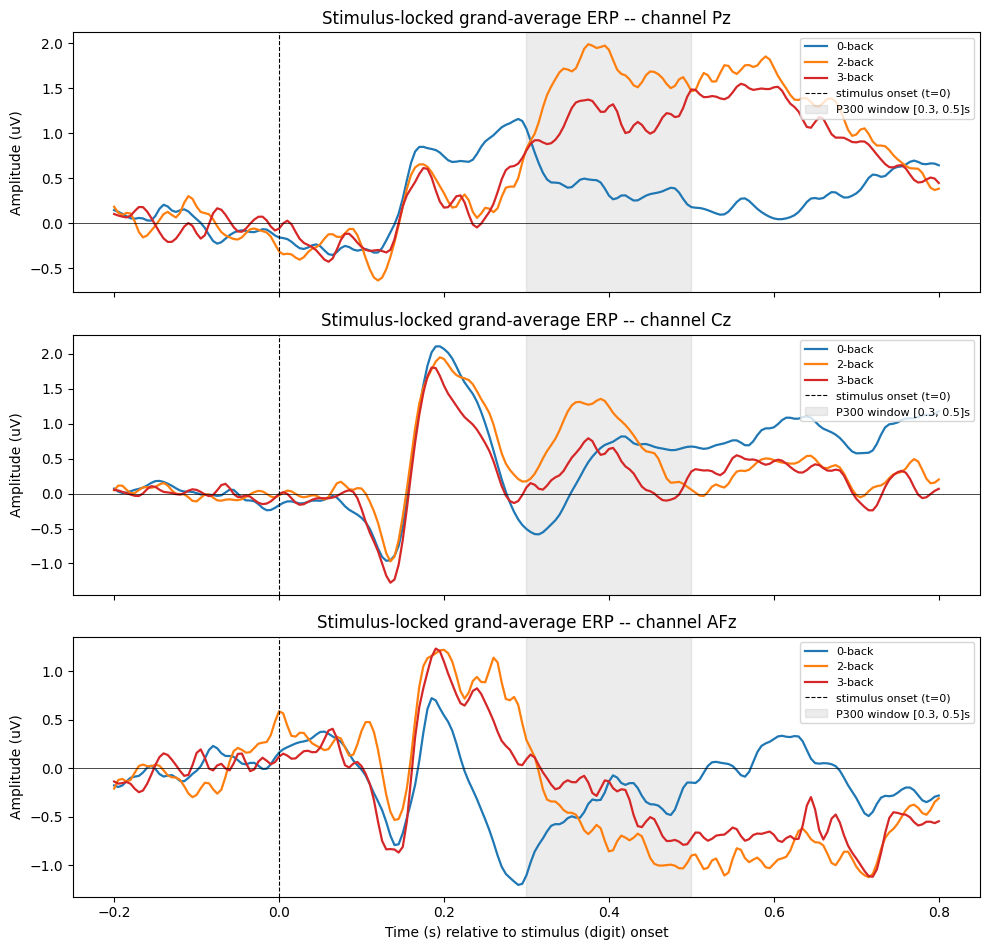


Plot also saved to run_d01b_stimulus_locked_erp.png

Mean P300-window amplitude per channel over (0.3, 0.5)s (uV):
    Pz: 0-back=+0.42  2-back=+1.61  3-back=+1.14  
        ordering: 2-back > 3-back > 0-back  (not monotonic)
    Cz: 0-back=+0.33  2-back=+0.75  3-back=+0.29  
        ordering: 2-back > 0-back > 3-back  (not monotonic)
   AFz: 0-back=-0.42  2-back=-0.63  3-back=-0.33  
        ordering: 3-back > 0-back > 2-back  (not monotonic)


In [9]:
"""
Run D0.1b -- Stimulus-locked (P300-style) ERP sanity check
FULLY SELF-CONTAINED CELL -- paste this ENTIRE content into ONE new Jupyter cell and run it.
No other file/import needed.

WHAT IT IS DIFFERENT FROM Run D0.1: that script epoched around the BLOCK onset (the 2s
instruction screen shown once per 40s n-back block, marker codes 112/128/144). That showed a
huge shared N1-P2 visual-onset response across all three classes, with only small/inconsistent
separation afterwards -- because block onset is NOT where cognitive-load differences are
expected. Classic n-back ERP literature (and Shin et al. 2018's own "target vs non-target"
analysis) locks epochs to EACH DIGIT PRESENTATION instead (one every 2s, ~20 per block), in a
short P300 window (-0.2 to 0.8s). Amplitude of the P300 (parietal-central, ~300-500ms
post-stimulus) is the classic marker that decreases monotonically with n-back load (Watter et
al. 2001; Kane & Engle). This script tests exactly that.

Stimulus-level marker codes -- TARGET-ONLY comparison (see IMPORTANT note below):
    16 = 0-back target
    48 = 2-back target
    80 = 3-back target
IMPORTANT (bug found and fixed here): an earlier version of this script pooled BOTH target and
non-target codes for the 2-back/3-back classes (48+64, 80+96) while 0-back only had a target
code (16) available in data_description.md's documented table. This created two problems:
  1. Each subject contributed TWO separate evoked entries for classes 1/2 (one per code) but
     only ONE for class 0 -- this is why the earlier run printed "52 subjects" for 2-back/3-back
     with only 26 real subjects (26 x 2 codes = 52 evoked entries, not 52 people).
  2. More importantly, it compared "0-back TARGET-ONLY trials" against "2-back/3-back TARGET+
     NON-TARGET POOLED trials" -- target stimuli evoke a substantially larger P300 (the classic
     oddball/target-detection effect) than non-target stimuli, independent of memory load. Pooling
     target+non-target for two classes but not the third confounds the load effect with this
     unrelated target/non-target effect, and can easily produce a non-monotonic, hard-to-interpret
     pattern that has nothing to do with cognitive load.
FIX: this version compares ONLY target-locked epochs (codes 16, 48, 80) across all three classes
-- a clean, symmetric, apples-to-apples P300-vs-load comparison, and each subject now
contributes exactly one evoked entry per class (like Run D0.1 did).
Non-target codes (64, 96) are still tallied and reported separately below (as
"excluded non-target codes"), not silently dropped without a trace.

DECISION RULE:
  - If P300 amplitude at Pz/Cz shows a monotonic 0-back > 2-back > 3-back (or consistent
    ordering) pattern in the 300-500ms window -> strong confirmation that cognitive-load signal
    IS present in the EEG, but is stimulus-locked, not block-uniform -> prioritize event-locked
    windowing (Run A1) for the model.
  - If no such ordering appears even here -> the load-related signal may be too weak/noisy at
    the single-stimulus ERP level for this dataset/preprocessing, and averaged-window approaches
    (e.g. spectral power over the whole block, as Shin et al. 2018 also used) may be a better
    target than trying to sharpen event-locked ERP windowing.

No GPU needed -- just matplotlib/mne/scipy on CPU, a few minutes.
"""

import os
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import mne

# ============================================================================
# EDIT THESE TO MATCH YOUR MAIN PREPROCESSING SCRIPT EXACTLY
# ============================================================================
BASE_DATASET_PATH = r"E:\kntu\Thesis\codes\DATA"                                  # raw dataset (needed only for re-reading markers)
OUTPUT_PATH       = r"F:\preprocessing-history-thesis\test0.0"       # where {VP}_eeg_clean_raw.fif files live

SUBJECTS = [f"VP{n:03d}" for n in range(1, 27)]   # narrow this down for a quicker test, e.g. range(1, 9)
CHANNELS = ['Pz', 'Cz', 'AFz']    # Pz/Cz are the classic P300 sites; AFz kept for comparison
TMIN, TMAX = -0.2, 0.8            # seconds, relative to EACH DIGIT presentation (classic P300 window)
BASELINE = (-0.2, 0.0)
SFREQ_EEG = 200.0                 # must match what preprocessing resampled EEG to
P300_WINDOW = (0.3, 0.5)          # seconds, classic P300 amplitude-measurement window
# ============================================================================

CLASS_NAMES = {0: '0-back', 1: '2-back', 2: '3-back'}
CLASS_COLORS = {0: 'tab:blue', 1: 'tab:orange', 2: 'tab:red'}

# CHANGED (bug fix, see docstring above): TARGET-ONLY codes, one code per class, symmetric.
STIM_CODE_TO_CLASS = {
    16: 0,   # 0-back target
    48: 1,   # 2-back target
    80: 2,   # 3-back target
}
NON_TARGET_CODES = {64: '2-back non-target', 96: '3-back non-target'}  # CHANGED: tracked separately, not pooled in
TRIAL_LEVEL_CODES = {112, 128, 144}   # block-onset codes, NOT stimulus-level -- excluded here on purpose


def load_eeg_markers(eeg_folder):
    """Minimal, self-contained re-read of ALL markers (any code) from mrk_nback.mat, at the SAME
    200Hz sample resolution the cleaned .fif files use. Filtering to specific codes happens
    later, in the main loop below.
    """
    cnt_path = os.path.join(eeg_folder, 'cnt_nback.mat')
    mrk_path = os.path.join(eeg_folder, 'mrk_nback.mat')

    mat_cnt = sio.loadmat(cnt_path, struct_as_record=False, squeeze_me=True)
    cnt_struct = mat_cnt[[k for k in mat_cnt.keys() if not k.startswith('__')][0]]
    sfreq_original = float(cnt_struct.fs)

    sfreq_for_markers = SFREQ_EEG if sfreq_original != SFREQ_EEG else sfreq_original

    mat_mrk = sio.loadmat(mrk_path, struct_as_record=False, squeeze_me=True)
    mrk_struct = mat_mrk[[k for k in mat_mrk.keys() if not k.startswith('__')][0]]

    if hasattr(mrk_struct, 'time'):
        event_positions = np.round(mrk_struct.time * sfreq_for_markers / 1000).astype(int)
    elif hasattr(mrk_struct, 'pos'):
        event_positions = np.array(mrk_struct.pos, dtype=int) - 1
    else:
        raise ValueError("Could not find 'time' or 'pos' in marker struct")

    if hasattr(mrk_struct, 'event') and hasattr(mrk_struct.event, 'desc'):
        desc = mrk_struct.event.desc
        if desc.ndim > 1:
            desc = desc.squeeze()
        event_codes = np.asarray(desc, dtype=int).flatten()
    else:
        event_codes = event_positions.copy()

    events = np.zeros((len(event_positions), 3), dtype=int)
    events[:, 0] = event_positions
    events[:, 2] = event_codes
    return events


evokeds_by_class = {0: [], 1: [], 2: []}   # each entry is one subject's averaged mne.Evoked
trial_counts_by_class = {0: 0, 1: 0, 2: 0}
n_subjects_used = 0
unmapped_codes_seen = set()
non_target_counts = {code: 0 for code in NON_TARGET_CODES}   # NEW: separate, explicit tally

for subject_id in SUBJECTS:
    fif_path = os.path.join(OUTPUT_PATH, subject_id, f"{subject_id}_eeg_clean_raw.fif")
    if not os.path.exists(fif_path):
        print(f"  [SKIP] {subject_id}: {subject_id}_eeg_clean_raw.fif not found")
        continue

    eeg_folder = os.path.join(BASE_DATASET_PATH, f"{subject_id}-EEG")
    if not os.path.exists(eeg_folder):
        print(f"  [SKIP] {subject_id}: raw EEG folder not found (needed for markers)")
        continue

    print(f"Processing {subject_id}...")

    raw_clean = mne.io.read_raw_fif(fif_path, preload=True, verbose=False)

    picks_available = [ch for ch in CHANNELS if ch in raw_clean.ch_names]
    if not picks_available:
        print(f"  [SKIP] {subject_id}: none of {CHANNELS} present after preprocessing")
        continue

    try:
        events = load_eeg_markers(eeg_folder)
    except Exception as e:
        print(f"  [SKIP] {subject_id}: could not load markers: {e}")
        continue

    # NEW: tally non-target codes explicitly (excluded from the P300 comparison on purpose, see
    # docstring), separately from truly-unmapped/unexpected codes.
    for code in NON_TARGET_CODES:
        non_target_counts[code] += int(np.sum(events[:, 2] == code))

    all_codes_seen = set(np.unique(events[:, 2]).tolist())
    handled_codes = set(STIM_CODE_TO_CLASS.keys()) | set(NON_TARGET_CODES.keys()) | TRIAL_LEVEL_CODES  # CHANGED: NON_TARGET_CODES no longer counted as "unmapped"
    unmapped_codes_seen |= (all_codes_seen - handled_codes)

    valid_codes = list(STIM_CODE_TO_CLASS.keys())
    target_events = events[np.isin(events[:, 2], valid_codes)]
    if len(target_events) == 0:
        print(f"  [SKIP] {subject_id}: no stimulus-level markers found")
        continue

    event_id = {str(code): code for code in valid_codes}
    try:
        epochs = mne.Epochs(
            raw_clean, target_events, event_id=event_id,
            tmin=TMIN, tmax=TMAX, baseline=BASELINE,
            picks=picks_available, preload=True, reject=None, verbose=False,
        )
    except Exception as e:
        print(f"  [SKIP] {subject_id}: error building epochs: {e}")
        continue

    if len(epochs) == 0:
        print(f"  [INFO] {subject_id}: 0/{len(target_events)} epochs survived "
              f"(likely all overlap BAD_* annotations, or fall outside the recording) -- skipped")
        continue

    subject_had_any = False
    for code, label in STIM_CODE_TO_CLASS.items():
        key = str(code)
        if key not in epochs.event_id or len(epochs[key]) == 0:
            continue
        evk = epochs[key].average()
        evokeds_by_class[label].append(evk)
        trial_counts_by_class[label] += len(epochs[key])
        subject_had_any = True

    if subject_had_any:
        n_subjects_used += 1

print(f"\n{n_subjects_used} subjects used.")
print("Total stimulus-level epochs collected per class:")
for label, name in CLASS_NAMES.items():
    print(f"  {name}: {trial_counts_by_class[label]} epochs from {len(evokeds_by_class[label])} subjects")

if unmapped_codes_seen:
    print(f"\n[NOTE] Marker codes seen in the data but NOT in STIM_CODE_TO_CLASS, "
          f"NON_TARGET_CODES, or TRIAL_LEVEL_CODES: {sorted(unmapped_codes_seen)}")
    print("       If any of these look like a missing '0-back non-target' code, this is expected "
          "and fine -- it is intentionally excluded from this target-only comparison.")

print(f"\n[INFO] Non-target codes seen (excluded from this comparison by design, see docstring):")
for code, desc in NON_TARGET_CODES.items():
    print(f"  code {code} ({desc}): {non_target_counts[code]} occurrences across all subjects")

if all(len(v) == 0 for v in evokeds_by_class.values()):
    raise RuntimeError("No evokeds were built for any class -- check paths / .fif files.")

# -- Grand average per class (mne auto-weights by each subject's trial count) --
grand_avg_by_class = {}
for label in CLASS_NAMES:
    if len(evokeds_by_class[label]) > 0:
        grand_avg_by_class[label] = mne.grand_average(evokeds_by_class[label])

# -- Plot: one subplot per channel, three classes overlaid --
fig, axes = plt.subplots(len(CHANNELS), 1, figsize=(10, 3.2 * len(CHANNELS)), sharex=True)
if len(CHANNELS) == 1:
    axes = [axes]

for ax, ch_name in zip(axes, CHANNELS):
    for label, name in CLASS_NAMES.items():
        if label not in grand_avg_by_class:
            continue
        evk = grand_avg_by_class[label]
        if ch_name not in evk.ch_names:
            continue
        ch_idx = evk.ch_names.index(ch_name)
        data_uv = evk.data[ch_idx] * 1e6   # volts -> microvolts for readability
        ax.plot(evk.times, data_uv, color=CLASS_COLORS[label], linewidth=1.6, label=name)

    ax.axvline(0.0, color='k', linestyle='--', linewidth=0.8, label='stimulus onset (t=0)')
    ax.axvspan(P300_WINDOW[0], P300_WINDOW[1], color='gray', alpha=0.15,
               label=f'P300 window [{P300_WINDOW[0]}, {P300_WINDOW[1]}]s')
    ax.axhline(0.0, color='k', linewidth=0.5)
    ax.set_title(f"Stimulus-locked grand-average ERP -- channel {ch_name}")
    ax.set_ylabel("Amplitude (uV)")
    ax.legend(loc='upper right', fontsize=8)

axes[-1].set_xlabel("Time (s) relative to stimulus (digit) onset")
plt.tight_layout()
plt.savefig("run_d01b_stimulus_locked_erp.png", dpi=150)
plt.show()
print("\nPlot also saved to run_d01b_stimulus_locked_erp.png")

# -- Quantitative P300 amplitude comparison: mean amplitude in the classic 300-500ms window --
print(f"\nMean P300-window amplitude per channel over {P300_WINDOW}s (uV):")
for ch_name in CHANNELS:
    row = f"  {ch_name:>4}: "
    values = {}
    for label, name in CLASS_NAMES.items():
        if label not in grand_avg_by_class or ch_name not in grand_avg_by_class[label].ch_names:
            row += f"{name}=N/A  "
            continue
        evk = grand_avg_by_class[label]
        ch_idx = evk.ch_names.index(ch_name)
        mask = (evk.times >= P300_WINDOW[0]) & (evk.times <= P300_WINDOW[1])
        mean_uv = evk.data[ch_idx, mask].mean() * 1e6
        values[label] = mean_uv
        row += f"{name}={mean_uv:+.2f}  "
    print(row)
    if len(values) == 3:
        ordering = sorted(values, key=lambda k: values[k], reverse=True)
        ordering_str = " > ".join(CLASS_NAMES[k] for k in ordering)
        monotonic = (values[0] >= values[1] >= values[2]) or (values[0] <= values[1] <= values[2])
        tag = "MONOTONIC with load (matches classic P300-vs-load literature)" if monotonic else "not monotonic"
        print(f"        ordering: {ordering_str}  ({tag})")

Processing VP001...
Processing VP002...
Processing VP003...
Processing VP004...
Processing VP005...
Processing VP006...
Processing VP007...
Processing VP008...
Processing VP009...
Processing VP010...
Processing VP011...
Processing VP012...
Processing VP013...
Processing VP014...
Processing VP015...
Processing VP016...
Processing VP017...
Processing VP018...
Processing VP019...
Processing VP020...
Processing VP021...
Processing VP022...
Processing VP023...
Processing VP024...
Processing VP025...
Processing VP026...

26 subjects used.
Total stimulus-level epochs collected per class:
  0-back: 4538 epochs from 26 subjects
  2-back: 4516 epochs from 26 subjects
  3-back: 4514 epochs from 26 subjects
Identifying common channels ...
Identifying common channels ...
Identifying common channels ...


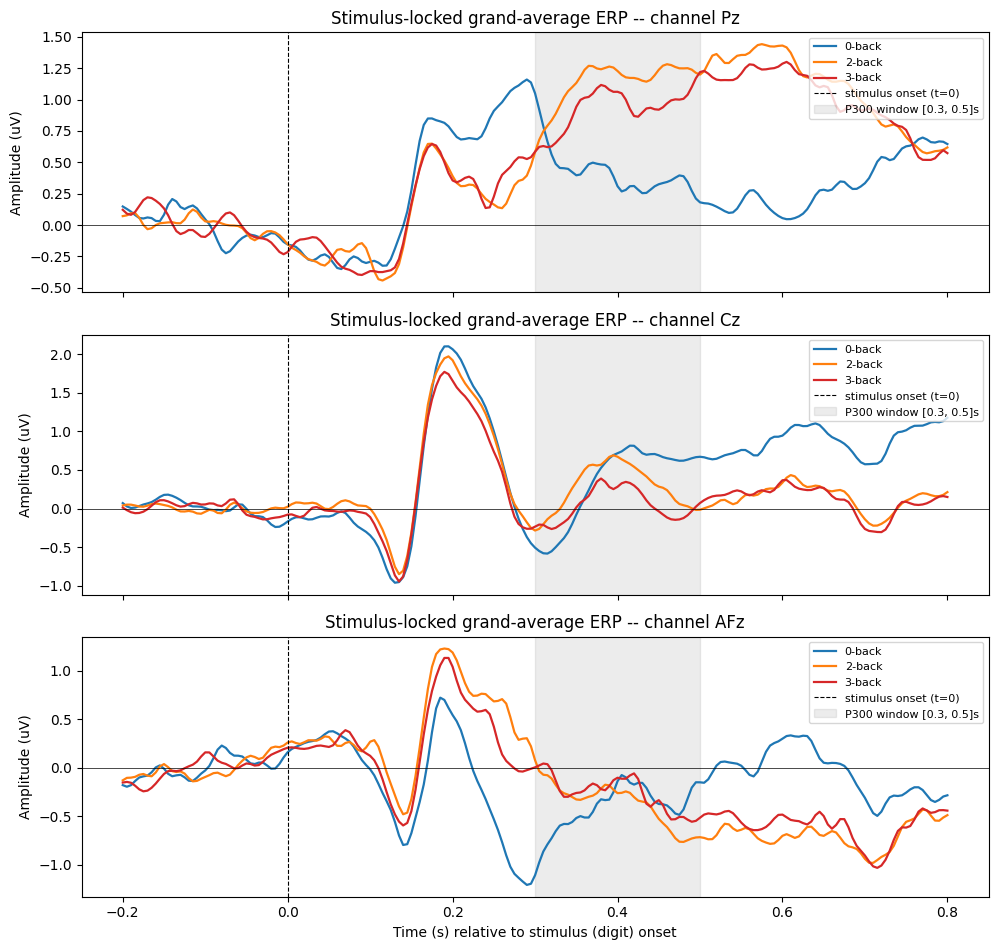


Plot also saved to run_d01b_stimulus_locked_erp.png

Mean P300-window amplitude per channel over (0.3, 0.5)s (uV):
    Pz: 0-back=+0.42  2-back=+1.13  3-back=+0.93  
        ordering: 2-back > 3-back > 0-back  (not monotonic)
    Cz: 0-back=+0.33  2-back=+0.27  3-back=+0.04  
        ordering: 0-back > 2-back > 3-back  (MONOTONIC with load (matches classic P300-vs-load literature))
   AFz: 0-back=-0.42  2-back=-0.36  3-back=-0.26  
        ordering: 3-back > 2-back > 0-back  (MONOTONIC with load (matches classic P300-vs-load literature))


In [10]:
"""
Run D0.1b -- Stimulus-locked (P300-style) ERP sanity check
FULLY SELF-CONTAINED CELL -- paste this ENTIRE content into ONE new Jupyter cell and run it.
No other file/import needed.

WHAT IT IS DIFFERENT FROM Run D0.1: that script epoched around the BLOCK onset (the 2s
instruction screen shown once per 40s n-back block, marker codes 112/128/144). That showed a
huge shared N1-P2 visual-onset response across all three classes, with only small/inconsistent
separation afterwards -- because block onset is NOT where cognitive-load differences are
expected. Classic n-back ERP literature (and Shin et al. 2018's own "target vs non-target"
analysis) locks epochs to EACH DIGIT PRESENTATION instead (one every 2s, ~20 per block), in a
short P300 window (-0.2 to 0.8s). Amplitude of the P300 (parietal-central, ~300-500ms
post-stimulus) is the classic marker that decreases monotonically with n-back load (Watter et
al. 2001; Kane & Engle). This script tests exactly that.

Stimulus-level marker codes:
    16 = 0-back (ALL digit presentations -- this dataset's marker scheme does NOT split
         0-back into target/non-target with separate codes, unlike 2-/3-back below)
    48 = 2-back target,  64 = 2-back non-target
    80 = 3-back target,  96 = 3-back non-target

IMPORTANT -- this script went through two earlier (flawed) versions before this one, kept here
as a record of what was tried and why it was wrong:
  v1: pooled target+non-target for 2-/3-back but only had a target code for 0-back -> each
      subject was double-counted for 2-/3-back (hence the earlier "52 subjects" bug), AND the
      comparison was asymmetric (0-back=target-only vs 2-/3-back=target+non-target pooled).
  v2 ("target-only" fix): restricted ALL classes to their target code (16, 48, 80) for symmetry.
      This looked right, but the actual trial COUNTS revealed the real problem: code 16 for
      0-back is not a "target-only" code at all -- its count (~4538, close to 26 subjects x 180
      trials/subject) shows it covers essentially ALL 0-back stimuli, not a ~30% target subset
      like 48/80 do for 2-/3-back. So v2 was STILL asymmetric, just flipped: 0-back=all stimuli
      vs 2-/3-back=rare oddball targets only (which have a known larger P300 from the oddball
      effect itself, independent of memory load) -- this alone can explain why 2-back > 3-back
      > 0-back was observed in v2, with no relation to cognitive load.
  v3 (THIS version, correct): compares ALL stimuli per class, symmetrically -- for 0-back this
      is just code 16 (as it always was), and for 2-/3-back this is target+non-target POOLED
      INTO ONE evoked per subject (not two separate evoked entries as in v1 -- each subject
      contributes exactly one evoked per class here, like Run D0.1 did). This treats "n-back
      difficulty level, averaged across everything that happens during it" symmetrically across
      all three classes, matching what the marker scheme actually gives us for 0-back.

DECISION RULE:
  - If P300 amplitude at Pz/Cz shows a monotonic 0-back > 2-back > 3-back (or consistent
    ordering) pattern in the 300-500ms window -> strong confirmation that cognitive-load signal
    IS present in the EEG, but is stimulus-locked, not block-uniform -> prioritize event-locked
    windowing (Run A1) for the model.
  - If no such ordering appears even here -> the load-related signal may be too weak/noisy at
    the single-stimulus ERP level for this dataset/preprocessing, and averaged-window approaches
    (e.g. spectral power over the whole block, as Shin et al. 2018 also used) may be a better
    target than trying to sharpen event-locked ERP windowing.

No GPU needed -- just matplotlib/mne/scipy on CPU, a few minutes.
"""

import os
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import mne

# ============================================================================
# EDIT THESE TO MATCH YOUR MAIN PREPROCESSING SCRIPT EXACTLY
# ============================================================================
BASE_DATASET_PATH = r"E:\kntu\Thesis\codes\DATA"                                  # raw dataset (needed only for re-reading markers)
OUTPUT_PATH       = r"F:\preprocessing-history-thesis\test0.0"       # where {VP}_eeg_clean_raw.fif files live

SUBJECTS = [f"VP{n:03d}" for n in range(1, 27)]   # narrow this down for a quicker test, e.g. range(1, 9)
CHANNELS = ['Pz', 'Cz', 'AFz']    # Pz/Cz are the classic P300 sites; AFz kept for comparison
TMIN, TMAX = -0.2, 0.8            # seconds, relative to EACH DIGIT presentation (classic P300 window)
BASELINE = (-0.2, 0.0)
SFREQ_EEG = 200.0                 # must match what preprocessing resampled EEG to
P300_WINDOW = (0.3, 0.5)          # seconds, classic P300 amplitude-measurement window
# ============================================================================

CLASS_NAMES = {0: '0-back', 1: '2-back', 2: '3-back'}
CLASS_COLORS = {0: 'tab:blue', 1: 'tab:orange', 2: 'tab:red'}

# CHANGED (v3, see docstring above): back to ALL FIVE codes mapped to their class -- but this
# time, all codes belonging to the SAME class are averaged together into ONE evoked per subject
# (see the main loop below), instead of creating one evoked per CODE like v1 did.
STIM_CODE_TO_CLASS = {
    16: 0,   # 0-back (all stimuli -- this dataset has no separate 0-back target/non-target code)
    48: 1,   # 2-back target
    64: 1,   # 2-back non-target
    80: 2,   # 3-back target
    96: 2,   # 3-back non-target
}
TRIAL_LEVEL_CODES = {112, 128, 144}   # block-onset codes, NOT stimulus-level -- excluded here on purpose


def load_eeg_markers(eeg_folder):
    """Minimal, self-contained re-read of ALL markers (any code) from mrk_nback.mat, at the SAME
    200Hz sample resolution the cleaned .fif files use. Filtering to specific codes happens
    later, in the main loop below.
    """
    cnt_path = os.path.join(eeg_folder, 'cnt_nback.mat')
    mrk_path = os.path.join(eeg_folder, 'mrk_nback.mat')

    mat_cnt = sio.loadmat(cnt_path, struct_as_record=False, squeeze_me=True)
    cnt_struct = mat_cnt[[k for k in mat_cnt.keys() if not k.startswith('__')][0]]
    sfreq_original = float(cnt_struct.fs)

    sfreq_for_markers = SFREQ_EEG if sfreq_original != SFREQ_EEG else sfreq_original

    mat_mrk = sio.loadmat(mrk_path, struct_as_record=False, squeeze_me=True)
    mrk_struct = mat_mrk[[k for k in mat_mrk.keys() if not k.startswith('__')][0]]

    if hasattr(mrk_struct, 'time'):
        event_positions = np.round(mrk_struct.time * sfreq_for_markers / 1000).astype(int)
    elif hasattr(mrk_struct, 'pos'):
        event_positions = np.array(mrk_struct.pos, dtype=int) - 1
    else:
        raise ValueError("Could not find 'time' or 'pos' in marker struct")

    if hasattr(mrk_struct, 'event') and hasattr(mrk_struct.event, 'desc'):
        desc = mrk_struct.event.desc
        if desc.ndim > 1:
            desc = desc.squeeze()
        event_codes = np.asarray(desc, dtype=int).flatten()
    else:
        event_codes = event_positions.copy()

    events = np.zeros((len(event_positions), 3), dtype=int)
    events[:, 0] = event_positions
    events[:, 2] = event_codes
    return events


evokeds_by_class = {0: [], 1: [], 2: []}   # each entry is one subject's averaged mne.Evoked
trial_counts_by_class = {0: 0, 1: 0, 2: 0}
n_subjects_used = 0
unmapped_codes_seen = set()

# CHANGED (v3): group the marker codes by class ONCE, up front, so the main loop always
# averages ALL codes belonging to a class into a SINGLE evoked per subject per class -- this is
# what actually fixes the double-counting bug (not just relying on there being one code per class).
codes_per_class = {label: [c for c, l in STIM_CODE_TO_CLASS.items() if l == label] for label in CLASS_NAMES}

for subject_id in SUBJECTS:
    fif_path = os.path.join(OUTPUT_PATH, subject_id, f"{subject_id}_eeg_clean_raw.fif")
    if not os.path.exists(fif_path):
        print(f"  [SKIP] {subject_id}: {subject_id}_eeg_clean_raw.fif not found")
        continue

    eeg_folder = os.path.join(BASE_DATASET_PATH, f"{subject_id}-EEG")
    if not os.path.exists(eeg_folder):
        print(f"  [SKIP] {subject_id}: raw EEG folder not found (needed for markers)")
        continue

    print(f"Processing {subject_id}...")

    raw_clean = mne.io.read_raw_fif(fif_path, preload=True, verbose=False)

    picks_available = [ch for ch in CHANNELS if ch in raw_clean.ch_names]
    if not picks_available:
        print(f"  [SKIP] {subject_id}: none of {CHANNELS} present after preprocessing")
        continue

    try:
        events = load_eeg_markers(eeg_folder)
    except Exception as e:
        print(f"  [SKIP] {subject_id}: could not load markers: {e}")
        continue

    all_codes_seen = set(np.unique(events[:, 2]).tolist())
    handled_codes = set(STIM_CODE_TO_CLASS.keys()) | TRIAL_LEVEL_CODES
    unmapped_codes_seen |= (all_codes_seen - handled_codes)

    valid_codes = list(STIM_CODE_TO_CLASS.keys())
    target_events = events[np.isin(events[:, 2], valid_codes)]
    if len(target_events) == 0:
        print(f"  [SKIP] {subject_id}: no stimulus-level markers found")
        continue

    event_id = {str(code): code for code in valid_codes}
    try:
        epochs = mne.Epochs(
            raw_clean, target_events, event_id=event_id,
            tmin=TMIN, tmax=TMAX, baseline=BASELINE,
            picks=picks_available, preload=True, reject=None, verbose=False,
        )
    except Exception as e:
        print(f"  [SKIP] {subject_id}: error building epochs: {e}")
        continue

    if len(epochs) == 0:
        print(f"  [INFO] {subject_id}: 0/{len(target_events)} epochs survived "
              f"(likely all overlap BAD_* annotations, or fall outside the recording) -- skipped")
        continue

    # CHANGED (v3, the actual fix): for each CLASS (not each code), select the union of all
    # codes belonging to that class in ONE go via epochs[[key1, key2, ...]], then average ONCE.
    # This guarantees exactly one evoked per subject per class, whether that class has one code
    # (0-back: just '16') or two (2-/3-back: target+non-target pooled together).
    subject_had_any = False
    for label, codes in codes_per_class.items():
        keys = [str(c) for c in codes if str(c) in epochs.event_id]
        keys = [k for k in keys if len(epochs[k]) > 0]
        if not keys:
            continue
        sub_epochs = epochs[keys]
        if len(sub_epochs) == 0:
            continue
        evk = sub_epochs.average()
        evokeds_by_class[label].append(evk)
        trial_counts_by_class[label] += len(sub_epochs)
        subject_had_any = True

    if subject_had_any:
        n_subjects_used += 1

print(f"\n{n_subjects_used} subjects used.")
print("Total stimulus-level epochs collected per class:")
for label, name in CLASS_NAMES.items():
    print(f"  {name}: {trial_counts_by_class[label]} epochs from {len(evokeds_by_class[label])} subjects")

if unmapped_codes_seen:
    print(f"\n[NOTE] Marker codes seen in the data but NOT in STIM_CODE_TO_CLASS or "
          f"TRIAL_LEVEL_CODES: {sorted(unmapped_codes_seen)}")

if all(len(v) == 0 for v in evokeds_by_class.values()):
    raise RuntimeError("No evokeds were built for any class -- check paths / .fif files.")

# -- Grand average per class (mne auto-weights by each subject's trial count) --
grand_avg_by_class = {}
for label in CLASS_NAMES:
    if len(evokeds_by_class[label]) > 0:
        grand_avg_by_class[label] = mne.grand_average(evokeds_by_class[label])

# -- Plot: one subplot per channel, three classes overlaid --
fig, axes = plt.subplots(len(CHANNELS), 1, figsize=(10, 3.2 * len(CHANNELS)), sharex=True)
if len(CHANNELS) == 1:
    axes = [axes]

for ax, ch_name in zip(axes, CHANNELS):
    for label, name in CLASS_NAMES.items():
        if label not in grand_avg_by_class:
            continue
        evk = grand_avg_by_class[label]
        if ch_name not in evk.ch_names:
            continue
        ch_idx = evk.ch_names.index(ch_name)
        data_uv = evk.data[ch_idx] * 1e6   # volts -> microvolts for readability
        ax.plot(evk.times, data_uv, color=CLASS_COLORS[label], linewidth=1.6, label=name)

    ax.axvline(0.0, color='k', linestyle='--', linewidth=0.8, label='stimulus onset (t=0)')
    ax.axvspan(P300_WINDOW[0], P300_WINDOW[1], color='gray', alpha=0.15,
               label=f'P300 window [{P300_WINDOW[0]}, {P300_WINDOW[1]}]s')
    ax.axhline(0.0, color='k', linewidth=0.5)
    ax.set_title(f"Stimulus-locked grand-average ERP -- channel {ch_name}")
    ax.set_ylabel("Amplitude (uV)")
    ax.legend(loc='upper right', fontsize=8)

axes[-1].set_xlabel("Time (s) relative to stimulus (digit) onset")
plt.tight_layout()
plt.savefig("run_d01b_stimulus_locked_erp.png", dpi=150)
plt.show()
print("\nPlot also saved to run_d01b_stimulus_locked_erp.png")

# -- Quantitative P300 amplitude comparison: mean amplitude in the classic 300-500ms window --
print(f"\nMean P300-window amplitude per channel over {P300_WINDOW}s (uV):")
for ch_name in CHANNELS:
    row = f"  {ch_name:>4}: "
    values = {}
    for label, name in CLASS_NAMES.items():
        if label not in grand_avg_by_class or ch_name not in grand_avg_by_class[label].ch_names:
            row += f"{name}=N/A  "
            continue
        evk = grand_avg_by_class[label]
        ch_idx = evk.ch_names.index(ch_name)
        mask = (evk.times >= P300_WINDOW[0]) & (evk.times <= P300_WINDOW[1])
        mean_uv = evk.data[ch_idx, mask].mean() * 1e6
        values[label] = mean_uv
        row += f"{name}={mean_uv:+.2f}  "
    print(row)
    if len(values) == 3:
        ordering = sorted(values, key=lambda k: values[k], reverse=True)
        ordering_str = " > ".join(CLASS_NAMES[k] for k in ordering)
        monotonic = (values[0] >= values[1] >= values[2]) or (values[0] <= values[1] <= values[2])
        tag = "MONOTONIC with load (matches classic P300-vs-load literature)" if monotonic else "not monotonic"
        print(f"        ordering: {ordering_str}  ({tag})")